# Ajuste del modelo y umbral de decisión

**Objetivo.** Partir del LGBM por defecto, ajustar sus hiperparámetros hasta el óptimo y fijar el
umbral de decisión. Todo se mide en validación; **2026 queda reservado para la prueba final**.

In [1]:
import json, sys
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "lib"))

from lightgbm import LGBMClassifier
from sklearn.metrics import (confusion_matrix, f1_score, precision_score,
                             recall_score)
from config import PROCESADOS, TAB, SEMILLA, aplicar_estilo
import graficos as g

aplicar_estilo()
train = pd.read_parquet(PROCESADOS / "modelado_train.parquet")
test = pd.read_parquet(PROCESADOS / "modelado_test.parquet")
print(f"train {train.shape} | test {test.shape}")

train (6879484, 37) | test (4608866, 37)


## 1. Protocolo

| Conjunto | Periodo | Uso |
|---|---|---|
| Ajuste | ene–oct 2025 | entrenar y buscar hiperparámetros |
| Validación | nov–dic 2025 | comparar etapas y elegir umbral |
| **Prueba** | ene–ago 2026 | **una sola medición al final** |

La métrica es el **F1 de la clase retrasada**; el umbral inicial es 0,50.

In [2]:
corte = pd.Timestamp("2025-11-01")
ajuste = train[train.fecha < corte]
valid = train[train.fecha >= corte]

X_aj, y_aj = ajuste.drop(columns=["arr_del15", "fecha"]), ajuste.arr_del15
X_va, y_va = valid.drop(columns=["arr_del15", "fecha"]), valid.arr_del15

# con todo tarda mucho, uso una muestra para buscar
sub = ajuste.sample(800_000, random_state=SEMILLA)
sub_val = valid.sample(200_000, random_state=SEMILLA)
X_s, y_s = sub.drop(columns=["arr_del15", "fecha"]), sub.arr_del15
X_sv, y_sv = sub_val.drop(columns=["arr_del15", "fecha"]), sub_val.arr_del15

print(f"ajuste {len(ajuste):,} | validación {len(valid):,} | búsqueda {len(sub):,}")
print(f"tardíos: ajuste {y_aj.mean()*100:.2f} % | validación {y_va.mean()*100:.2f} % | test {test.arr_del15.mean()*100:.2f} %")

ajuste 5,752,264 | validación 1,127,220 | búsqueda 800,000
tardíos: ajuste 22.03 % | validación 23.71 % | test 23.56 %


In [3]:
def puntuar(modelo, X, y, umbral=0.5):
    probs = modelo.predict_proba(X)[:, 1]
    return f1_score(y, (probs >= umbral).astype(int))


etapas = []
base = LGBMClassifier(n_estimators=300, learning_rate=0.1, n_jobs=-1,
                      verbose=-1, random_state=SEMILLA).fit(X_s, y_s)
f1_base = puntuar(base, X_sv, y_sv)
etapas.append({"etapa": "0. LGBM por defecto", "F1": f1_base})
print(f"por defecto: F1 {f1_base:.3f}")

por defecto: F1 0.506


## 2. Búsqueda aleatoria

Primer acercamiento: 20 combinaciones al azar sobre el mismo espacio de búsqueda. Sirve de
referencia para saber si la optimización bayesiana aporta algo.

In [4]:
rng = np.random.default_rng(SEMILLA)

def muestra_params(rng):
    return {"num_leaves": int(rng.integers(15, 200)),
            "learning_rate": float(rng.uniform(.03, .2)),
            "n_estimators": int(rng.integers(200, 700)),
            "min_child_samples": int(rng.integers(20, 200)),
            "feature_fraction": float(rng.uniform(.6, 1.)),
            "bagging_fraction": float(rng.uniform(.6, 1.)),
            "bagging_freq": 1,
            "reg_lambda": float(rng.uniform(0, 10))}

historial_rand, mejor_rand, f1_rand = [], None, 0.0
for _ in range(20):
    params = muestra_params(rng)
    m = LGBMClassifier(n_jobs=-1, verbose=-1, random_state=SEMILLA, **params).fit(X_s, y_s)
    f1 = puntuar(m, X_sv, y_sv)
    historial_rand.append(f1)
    if f1 > f1_rand:
        mejor_rand, f1_rand = params, f1

etapas.append({"etapa": "1. Búsqueda aleatoria (20)", "F1": f1_rand})
print(f"aleatoria: F1 {f1_rand:.3f}")

aleatoria: F1 0.509


## 3. Optuna (optimización bayesiana)

Optuna aprende de los intentos anteriores: propone combinaciones cercanas a las buenas y explora
donde hay incertidumbre. Se ejecutan 40 intentos sobre la misma submuestra.

In [5]:
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

def objetivo(t):
    params = {"num_leaves": t.suggest_int("num_leaves", 15, 255),
              "learning_rate": t.suggest_float("learning_rate", .03, .2, log=True),
              "n_estimators": t.suggest_int("n_estimators", 200, 700),
              "min_child_samples": t.suggest_int("min_child_samples", 20, 200),
              "feature_fraction": t.suggest_float("feature_fraction", .6, 1.),
              "bagging_fraction": t.suggest_float("bagging_fraction", .6, 1.),
              "bagging_freq": 1,
              "reg_lambda": t.suggest_float("reg_lambda", 0, 10)}
    m = LGBMClassifier(n_jobs=-1, verbose=-1, random_state=SEMILLA, **params).fit(X_s, y_s)
    return f1_score(y_sv, m.predict(X_sv))

estudio = optuna.create_study(direction="maximize",
                              sampler=optuna.samplers.TPESampler(seed=SEMILLA))
estudio.optimize(objetivo, n_trials=40, show_progress_bar=False)
print(f"mejor F1: {estudio.best_value:.3f} | intentos: {len(estudio.trials)}")
print(estudio.best_params)

mejor F1: 0.510 | intentos: 40
{'num_leaves': 110, 'learning_rate': 0.15485459056282652, 'n_estimators': 569, 'min_child_samples': 57, 'feature_fraction': 0.6075522894021597, 'bagging_fraction': 0.6908836541187742, 'reg_lambda': 9.394510502801246}


## 4. Umbral de decisión

El modelo devuelve una probabilidad; el umbral decide cuándo se avisa. Con clases desbalanceadas,
0,50 no tiene por qué ser el mejor: se recorre 0,20–0,80 en validación.

In [6]:
mejor = LGBMClassifier(n_jobs=-1, verbose=-1, random_state=SEMILLA,
                       **estudio.best_params).fit(X_s, y_s)
probs = mejor.predict_proba(X_sv)[:, 1]

umbrales = np.arange(.20, .81, .01)
f1s = [f1_score(y_sv, (probs >= u).astype(int)) for u in umbrales]
u_opt = float(umbrales[int(np.argmax(f1s))])
f1_opt = max(f1s)
etapas.append({"etapa": "2. Optuna (40)", "F1": estudio.best_value})
etapas.append({"etapa": f"3. + umbral {u_opt:.2f}", "F1": f1_opt})
print(f"umbral 0,50 → F1 {f1_score(y_sv, (probs>=.5).astype(int)):.3f}")
print(f"umbral {u_opt:.2f} → F1 {f1_opt:.3f}")

umbral 0,50 → F1 0.507
umbral 0.28 → F1 0.554


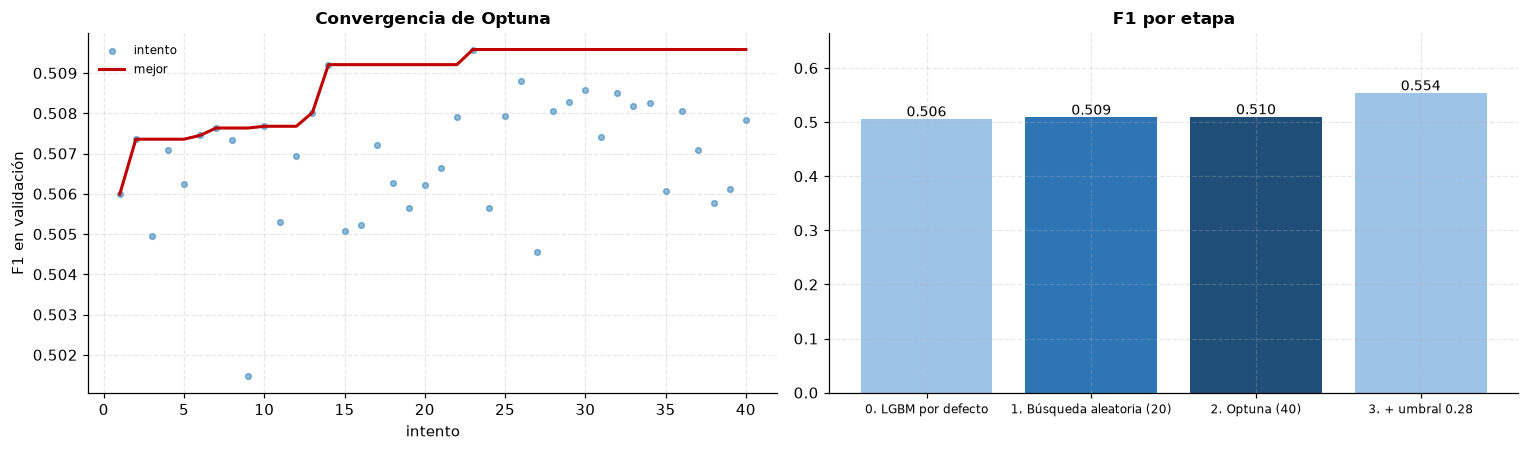

In [7]:
pd.DataFrame({"intento": range(1, len(estudio.trials) + 1),
              "f1": [t.value for t in estudio.trials]}).to_csv(
    TAB / "05_optuna_trials.csv", index=False, sep=";", decimal=",", encoding="utf-8-sig")
valores = [t.value for t in estudio.trials]
mejor_acumulado = np.maximum.accumulate(valores)

fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
ax[0].scatter(range(1, len(valores) + 1), valores, s=14, alpha=.5, label="intento")
ax[0].plot(range(1, len(valores) + 1), mejor_acumulado, color="#c00000", lw=2, label="mejor")
ax[0].set_title("Convergencia de Optuna")
ax[0].set_xlabel("intento"); ax[0].set_ylabel("F1 en validación"); ax[0].legend(fontsize=8)

etapas_graf = pd.DataFrame(etapas)
ax[1].bar(etapas_graf.etapa, etapas_graf.F1, color=["#9dc3e6", "#2e75b6", "#1f4e79"])
ax[1].set_ylim(0, max(etapas_graf.F1) * 1.2)
ax[1].set_title("F1 por etapa")
ax[1].tick_params(axis="x", labelsize=8)
for i, v in enumerate(etapas_graf.F1):
    ax[1].text(i, v + .005, f"{v:.3f}", ha="center", fontsize=9)
g.guardar(fig, "14_optuna.png")
plt.show()

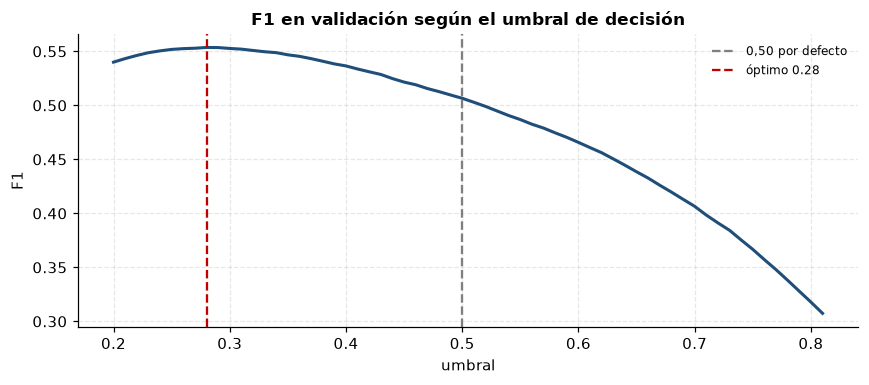

In [8]:
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(umbrales, f1s, color="#1f4e79", lw=2)
ax.axvline(.5, color="#7f7f7f", ls="--", label="0,50 por defecto")
ax.axvline(u_opt, color="#c00000", ls="--", label=f"óptimo {u_opt:.2f}")
ax.set_title("F1 en validación según el umbral de decisión")
ax.set_xlabel("umbral"); ax.set_ylabel("F1"); ax.legend(fontsize=8)
g.guardar(fig, "15_umbral.png")
plt.show()

## 5. Modelo final y prueba en 2026

Se reentrena con **todo 2025** (ajuste + validación) y los mejores hiperparámetros, y se mide una
sola vez sobre 2026 con el umbral elegido.

In [9]:
final = LGBMClassifier(n_jobs=-1, verbose=-1, random_state=SEMILLA,
                       **estudio.best_params).fit(X_aj, y_aj)
X_test, y_test = test.drop(columns=["arr_del15", "fecha"]), test.arr_del15
probs_test = final.predict_proba(X_test)[:, 1]

pred_50 = (probs_test >= .5).astype(int)
pred_opt = (probs_test >= u_opt).astype(int)
print(f"test 2026 (umbral 0,50): F1 {f1_score(y_test, pred_50):.3f}")
print(f"test 2026 (umbral {u_opt:.2f}): F1 {f1_score(y_test, pred_opt):.3f} | "
      f"precisión {precision_score(y_test, pred_opt):.3f} | recall {recall_score(y_test, pred_opt):.3f}")
print(pd.DataFrame(confusion_matrix(y_test, pred_opt), index=["real 0", "real 1"],
                   columns=["pred 0", "pred 1"]))

test 2026 (umbral 0,50): F1 0.508


test 2026 (umbral 0.28): F1 0.553 | precisión 0.547 | recall 0.559


         pred 0  pred 1
real 0  3020569  502478
real 1   478873  606946


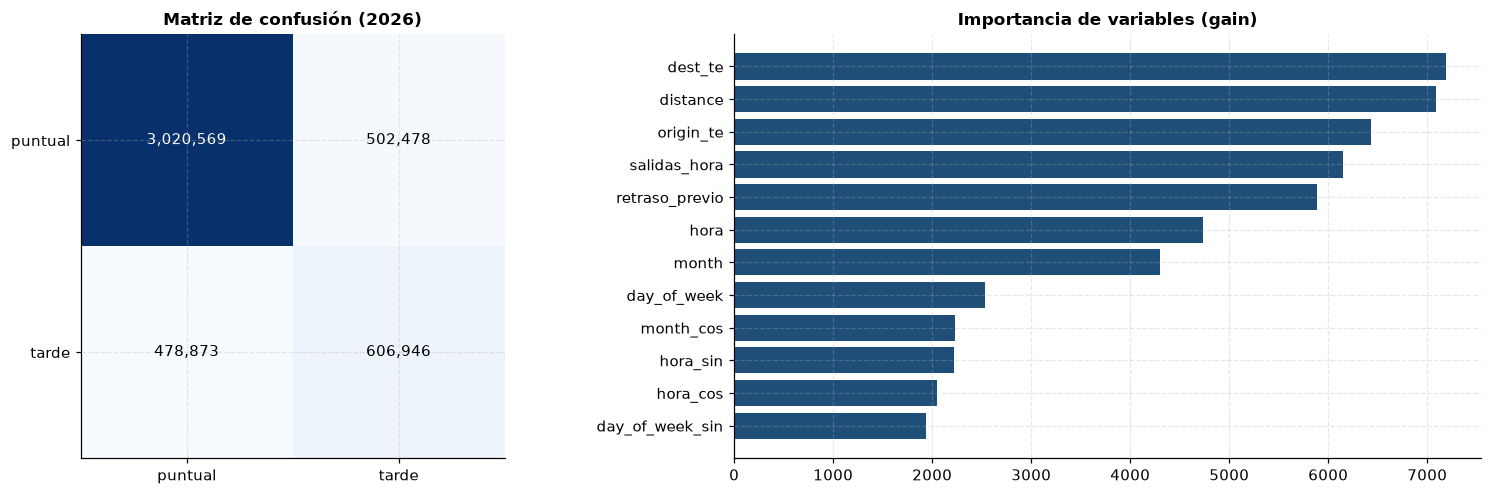

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(14.5, 4.6))
mc = confusion_matrix(y_test, pred_opt)
ax[0].imshow(mc, cmap="Blues")
ax[0].set_xticks([0, 1], ["puntual", "tarde"]); ax[0].set_yticks([0, 1], ["puntual", "tarde"])
ax[0].set_title("Matriz de confusión (2026)")
for i in range(2):
    for j in range(2):
        ax[0].text(j, i, f"{mc[i, j]:,}", ha="center", va="center",
                   color="white" if mc[i, j] > mc.max() / 2 else "black")

imp = pd.Series(final.feature_importances_, index=X_test.columns).sort_values().tail(12)
ax[1].barh(imp.index, imp.values, color="#1f4e79")
ax[1].set_title("Importancia de variables (gain)")
g.guardar(fig, "16_resultado.png")
plt.show()

## 6. Guardar y concluir

**Qué muestra el recorrido.** Los valores por defecto dejan el F1 en 0,506; la búsqueda aleatoria
sube a 0,509; Optuna afina hasta 0,510 (una meseta: +0,004 en total) y el umbral elegido en
validación lleva el F1 a 0,554. En 2026 se obtiene 0,553, casi idéntico: el ajuste no se memorizó.
El umbral aporta diez veces más que los hiperparámetros.


In [11]:
import json
etapas_df = pd.DataFrame(etapas).round(4)
etapas_df.to_csv(TAB / "05_etapas_modelo.csv", index=False, sep=";", decimal=",", encoding="utf-8-sig")
imp.sort_values(ascending=False).head(15).to_csv(TAB / "06_importancia_variables.csv", sep=";", decimal=",", encoding="utf-8-sig")

final.booster_.save_model(str(RAIZ / "models" / "lgbm_final.txt"))
(RAIZ / "models" / "lgbm_final.json").write_text(json.dumps({
    "modelo": "LGBMClassifier", "params": estudio.best_params, "umbral": u_opt,
    "f1_test": float(f1_score(y_test, pred_opt)),
}, indent=2), encoding="utf-8")

etapas_df

,etapa,F1
0,0. LGBM por defecto,0.5057
1,1. Búsqueda aleatoria (20),0.5087
2,2. Optuna (40),0.5096
3,3. + umbral 0.28,0.5536
